# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [22]:
# Importar librerías
import pandas as pd
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt

### Cargar Dataset

In [23]:
# Cargar el dataset y explorar datos
df = pd.read_csv("/datasets/novaretail_comportamiento_clientes_2024.csv")
df.info()
nova_r= df

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [24]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio

Recuerda eliminar este bloque de texto antes de subir el proyecto a tu portafolio.


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- 

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna ... .


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [25]:
# Corregir el tipo de dato
nova_r['id_cliente'] = nova_r['id_cliente'].astype('string')
nova_r['edad'] = nova_r['edad'].astype('int64')
nova_r['satisfaccion'] = nova_r['satisfaccion'].astype('int64')
nova_r['miembro_premium'] = nova_r['miembro_premium'].astype('bool')
nova_r['abandono'] = nova_r['abandono'].astype('bool')
nova_r['tipo_dispositivo'] = nova_r['tipo_dispositivo'].astype('category')
nova_r['region'] = nova_r['region'].astype('category')

In [26]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   id_cliente                 15000 non-null  string  
 1   edad                       15000 non-null  int64   
 2   nivel_ingreso              15000 non-null  float64 
 3   visitas_mes                15000 non-null  int64   
 4   compras_mes                15000 non-null  int64   
 5   gasto_publicidad_dirigida  15000 non-null  float64 
 6   satisfaccion               15000 non-null  int64   
 7   miembro_premium            15000 non-null  bool    
 8   abandono                   15000 non-null  bool    
 9   tipo_dispositivo           15000 non-null  category
 10  region                     15000 non-null  category
 11  ingreso_anual              15000 non-null  float64 
dtypes: bool(2), category(2), float64(3), int64(4), string(1)
memory usage: 996.5 KB


#### Explorar variables numéricas

In [27]:
# Estadísticas descriptivas de variables numéricas
variables_numericas = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes', 
                       'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']
print(nova_r[variables_numericas].describe())




               edad  nivel_ingreso   visitas_mes   compras_mes  \
count  15000.000000   15000.000000  15000.000000  15000.000000   
mean      38.262400   30019.704782     10.029000      1.206467   
std       11.492378    9833.166305      3.158189      1.105284   
min       18.000000    8000.000000      1.000000      0.000000   
25%       30.000000   23127.097500      8.000000      0.000000   
50%       38.000000   30023.745000     10.000000      1.000000   
75%       46.000000   36768.440000     12.000000      2.000000   
max       75.000000   74790.840000     25.000000      8.000000   

       gasto_publicidad_dirigida  satisfaccion  ingreso_anual  
count               15000.000000  15000.000000   15000.000000  
mean                   20.149301      3.160067      36.594180  
std                    10.880724      0.753978      34.484888  
min                     0.000000      1.000000       0.000000  
25%                    12.310000      3.000000       0.000000  
50%                  


Diagnóstico inicial de variables numéricas

- `Edad`: Los clientes tienen edades bastante variadas y están distribuidas de manera equilibrada.
- `Nivel de ingreso`: La media ($30,019) y la mediana ($30,023) son prácticamente iguales, lo que indica que los ingresos de los clientes son bastante similares y no hay grandes diferencias entre ellos.
- `Visitas al mes`: Los clientes visitan regularmente, aproximadamente 10 veces al mes, es decir, unas 2–3 veces por semana. La media y la mediana coinciden.
- `Compras al mes`: El 25% de los clientes no realiza ninguna compra, aunque sí visita el negocio. Esto muestra que existe un grupo de clientes que está interesado, pero que todavía no está convirtiendo sus visitas en compras.
- `Gasto en publicidad dirigida`: El gasto varía bastante, desde $0 hasta $75.51. Una parte de los clientes recibe poca inversión publicitaria, lo que podría estar relacionado con una menor cantidad de compras.
- `Satisfacción`: La satisfacción promedio es de 3.16 sobre 5, por lo que los clientes están relativamente satisfechos, pero todavía existe un margen importante para mejorar su experiencia.
- `Ingreso anual`: El 25% de los clientes no genera ingresos, mientras que la mayoría genera cantidades relativamente bajas. Los ingresos están concentrados principalmente en un grupo pequeño de clientes que genera mucho más que el resto.

#### Explorar variables binarias

In [28]:
# Verificar que cada columna tenga únicamente dos valores posibles
variables_binarias = ['miembro_premium', 'abandono']

for col in variables_binarias:
    print(f"\n✓ {col}:")
    print(f"  Valores únicos: {nova_r[col].unique()}")
    print(f"  Conteo:\n{nova_r[col].value_counts().sort_index()}")
    print(f"  Tipo: {nova_r[col].dtype}")


✓ miembro_premium:
  Valores únicos: [False  True]
  Conteo:
False    12911
True      2089
Name: miembro_premium, dtype: int64
  Tipo: bool

✓ abandono:
  Valores únicos: [False  True]
  Conteo:
False    12739
True      2261
Name: abandono, dtype: int64
  Tipo: bool



Diagnóstico inicial de variables binarias

- `miembro_premium` — DESEQUILIBRIO EXTREMO. El 86% de la base son clientes sin suscripción premium. Esta minoría de premium (13.9%) podría ser desproporcionadamente importante para los ingresos, pero requiere validación en correlación con ingreso_anual.
- `abandono` — Tasa de churn del 15.1%. Aproximadamente 1 de cada 7 clientes abandona. Esta es una métrica crítica: sugiere que la plataforma tiene un desafío significativo de retención. La relación entre abandono y las otras variables (visitas, compras, satisfacción) son clave para entender qué predice la deserción.

#### Explorar variables categóricas

In [29]:
# Verificar el número de valores únicos por variable categórica
variables_categoricas = ['id_cliente', 'tipo_dispositivo', 'region']

for col in ['tipo_dispositivo', 'region']:
    print(f"{col}: {nova_r[col].nunique()} valores únicos")

tipo_dispositivo: 3 valores únicos
region: 4 valores únicos


In [30]:
# Explorar variables categóricas y cómo se distribuyen
for col in variables_categoricas:
    print(f"\n✓ {col}:")
    print(f"  Valores únicos: {nova_r[col].nunique()}")
    print(f"  Tipo: {nova_r[col].dtype}")
    print(f"  Conteo:")
    print(nova_r[col].value_counts())
    
    


✓ id_cliente:
  Valores únicos: 15000
  Tipo: string
  Conteo:
CL-107556    1
CL-109090    1
CL-101662    1
CL-105127    1
CL-100632    1
            ..
CL-102613    1
CL-110869    1
CL-108872    1
CL-105669    1
CL-104659    1
Name: id_cliente, Length: 15000, dtype: Int64

✓ tipo_dispositivo:
  Valores únicos: 3
  Tipo: category
  Conteo:
móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64

✓ region:
  Valores únicos: 4
  Tipo: category
  Conteo:
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64



Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` — Los clientes acceden principalmente desde dispositivos móviles (2 de cada 3 clientes). Tablet representa apenas 1 de cada 10 clientes, sugeriendo que la plataforma está optimizada o predominantemente utilizada en móvil. Esto es relevante para analizar si hay diferencias en comportamiento o ingresos según dispositivo.
- `region` - A diferencia de tipo_dispositivo, las 4 regiones están distribuidas de forma más uniforme (rango: 20.46% - 29.30%). Sin embargo, la región Norte sobrerrepresenta (~29%), mientras que Este está subrepresentada (~20%). Esto sugiere que la base de clientes no es homogénea geográficamente, dato importante para análisis regionales.



### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.


## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

CORRELACIÓN PEARSON (Relaciones lineales - Variables numéricas):
                               edad  nivel_ingreso  visitas_mes  compras_mes  \
edad                       1.000000      -0.009003     0.004998     0.014971   
nivel_ingreso             -0.009003       1.000000     0.001060     0.007309   
visitas_mes                0.004998       0.001060     1.000000     0.353844   
compras_mes                0.014971       0.007309     0.353844     1.000000   
gasto_publicidad_dirigida  0.000062       0.016834     0.578947     0.207528   
satisfaccion              -0.005986       0.000628    -0.005645    -0.005898   
ingreso_anual              0.017496       0.017446     0.337147     0.967149   

                           gasto_publicidad_dirigida  satisfaccion  \
edad                                        0.000062     -0.005986   
nivel_ingreso                               0.016834      0.000628   
visitas_mes                                 0.578947     -0.005645   
compras_mes   

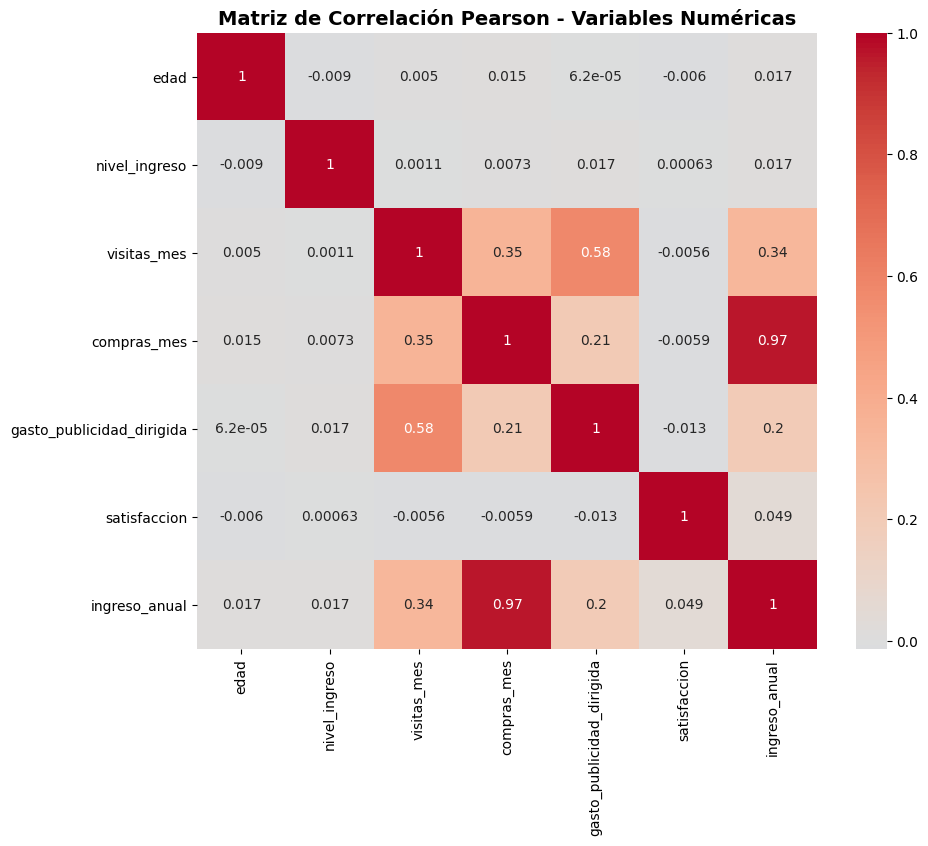

CORRELACIÓN SPEARMAN (Relaciones monótonas - Variables numéricas):
                               edad  nivel_ingreso  visitas_mes  compras_mes  \
edad                       1.000000      -0.007775     0.005205     0.015630   
nivel_ingreso             -0.007775       1.000000     0.001420     0.009004   
visitas_mes                0.005205       0.001420     1.000000     0.332943   
compras_mes                0.015630       0.009004     0.332943     1.000000   
gasto_publicidad_dirigida  0.002869       0.015393     0.559267     0.192511   
satisfaccion              -0.006161       0.004861    -0.002014    -0.003245   
ingreso_anual              0.016097       0.025017     0.320954     0.967482   

                           gasto_publicidad_dirigida  satisfaccion  \
edad                                        0.002869     -0.006161   
nivel_ingreso                               0.015393      0.004861   
visitas_mes                                 0.559267     -0.002014   
compras_mes 

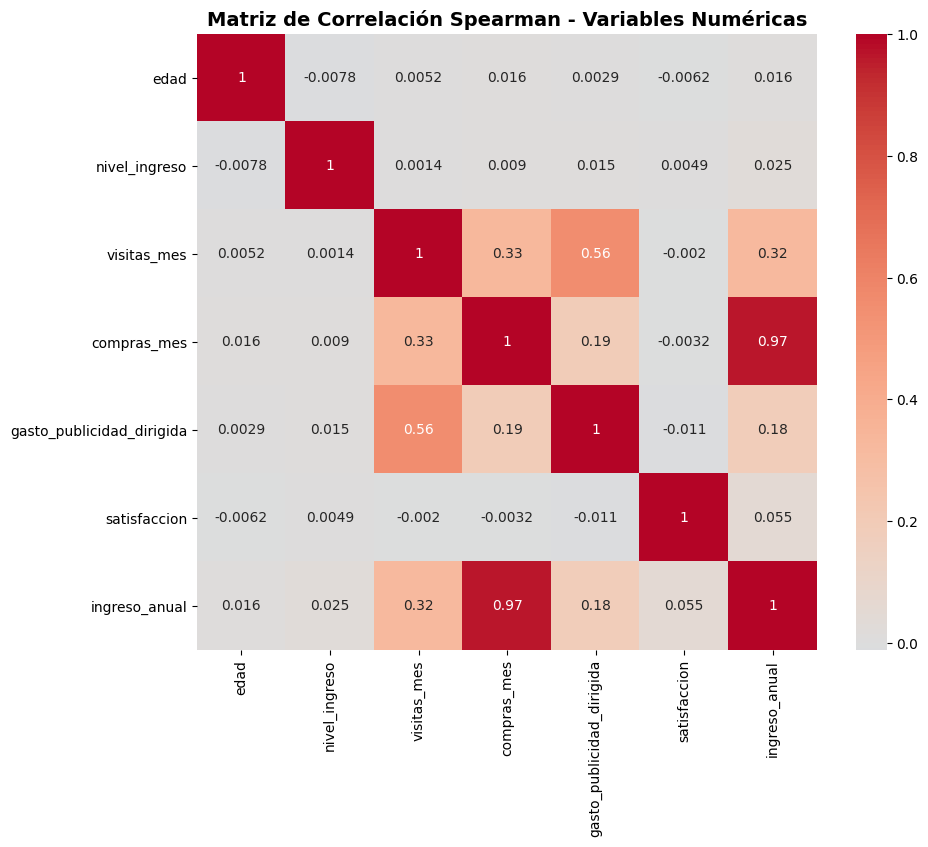

In [31]:
# Visualizar la matriz de correlación para identificar relaciones
# Correlacion pearson
print("CORRELACIÓN PEARSON (Relaciones lineales - Variables numéricas):")
variables_numericas = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes', 
                       'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']

corr_pearson = nova_r[variables_numericas].corr(method='pearson')
print(corr_pearson)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_pearson, annot=True, cmap='coolwarm', center=0)
plt.title('Matriz de Correlación Pearson - Variables Numéricas', fontweight='bold', fontsize=14)
plt.show()

# Correlacion separman
print("CORRELACIÓN SPEARMAN (Relaciones monótonas - Variables numéricas):")
corr_spearman = nova_r[variables_numericas].corr(method='spearman')
print(corr_spearman)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_spearman, annot=True, cmap='coolwarm', center=0)
plt.title('Matriz de Correlación Spearman - Variables Numéricas', fontweight='bold', fontsize=14)
plt.show()



Observaciones generales (Heatmap)  
- Se observa que Pearson y Spearman son prácticamente idénticas, indicando que las relaciones son lineales y monótonas, sin necesidad de transformaciones complejas.
- La matriz presenta una estructura clara de independencia: la mayoría de variables tienen correlaciones muy cercanas a cero (±0.0x), salvo algunas excepciones notables.
- Relaciones internas fuertes:
gasto_publicidad_dirigida ↔ visitas_mes (0.579): Clientes que reciben más publicidad tienden a visitar más la plataforma.
visitas_mes ↔ compras_mes (0.354): Más visitas se asocian con más compras, pero la relación es moderada (no es determinante).


Observaciones respecto a `ingreso_anual`  
- ingreso_anual está dominado casi exclusivamente por compras_mes (r=0.967), explicando el 94% de su varianza. Las visitas tienen una asociación moderada (r=0.337) pero débil comparada con compras, mientras que la publicidad dirigida muestra poca relación (r=0.197). Sorprendentemente, satisfaccion es prácticamente independiente de ingresos (r=0.049), y los atributos demográficos como edad e ingreso personal del cliente son irrelevantes (r≈0.017).


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- No es necesario hacer un scatterplot ya que solo mostrarian ruido disperso sin patron dicernible, en cambio para compras_mes vs ingreso_anual hay un r=0.96 ya que es una correlacion casi perfceta y requiere verificarse.

### Scatterplot para pares clave

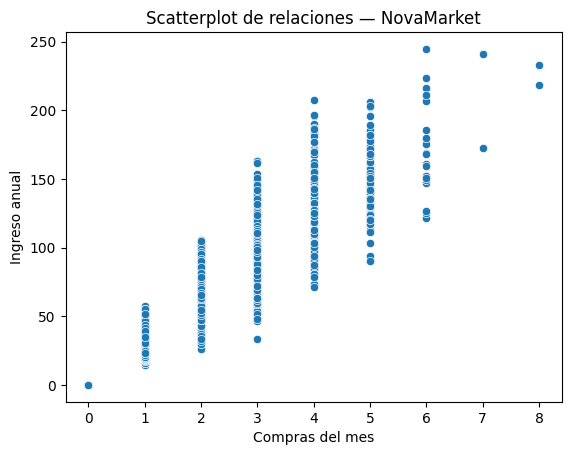

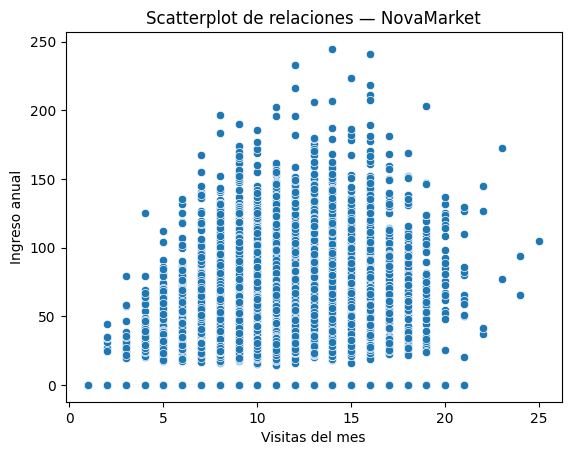

In [32]:
# Visualizar pares de variables con relaciones moderadas o fuertes
# Scatterplot compras_mes vs ingreso_anual
sns.scatterplot(
    data=nova_r,
    x="compras_mes",
    y="ingreso_anual"
)

plt.title("Scatterplot de relaciones — NovaMarket")
plt.xlabel("Compras del mes")
plt.ylabel("Ingreso anual")
plt.show()

# Scatterplot visitas_mes vs ingreso_anual
sns.scatterplot(
    data=nova_r,
    x="visitas_mes",
    y="ingreso_anual"
)

plt.title("Scatterplot de relaciones — NovaMarket")
plt.xlabel("Visitas del mes")
plt.ylabel("Ingreso anual")
plt.show()


Observaciones iniciales (Scatterplot)

**compras_mes vs ingreso_anual**
- Dirección: Positiva muy fuerte — A mayor número de compras, mayor ingreso anual generado.
- Dispersión: Muy baja — Los puntos se agrupan en líneas verticales nítidas y bien definidas, una para cada valor de compras (0, 1, 2, 3... 8). Esto indica una relación casi determinística.
- Outliers: Presentes pero limitados — Hay algunos puntos dispersos por encima de las líneas principales (clientes con pocas compras pero ingresos altos), pero representan excepciones claras. La mayor concentración de outliers está en 6-8 compras.
- Colinealidad: Extremadamente alta — La correlación r=0.967 se confirma visualmente. La relación es prácticamente 1:1; cada incremento en compras predice con precisión el incremento en ingresos. Sugiere que ingreso_anual podría calcularse directamente de compras_mes.

**visitas_mes vs ingreso_anual**
- Dirección: Positiva débil — Existe una tendencia general al alza, pero mucho menos clara y pronunciada que en compras.
- Dispersión: Muy alta — Para un mismo número de visitas hay una gran variación en ingresos. Por ejemplo, clientes con 10 visitas generan ingresos que van desde ~$20 hasta ~$220, una dispersión enorme.
- Outliers: Abundantes — Hay muchos puntos que se desvían del patrón esperado, especialmente en los extremos (visitas altas con ingresos bajos, o visitas moderadas con ingresos altos). No son excepciones sino parte del patrón.
- Colinealidad: Baja a media — La correlación r=0.337 se confirma visualmente. Las visitas explican poco de la varianza en ingresos; el 63% de la variabilidad permanece inexplicado. Esto indica que visitas es un predictor pobre y que otros factores (como el tipo de cliente o tasa de conversión) son mucho más importantes.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [33]:
# Calcular correlación entre variables relevantes
corr_pearson_compras  = nova_r['compras_mes'].corr(nova_r['ingreso_anual'], method='pearson')
print(f"Correlacion entre: compras_mes y ingreso_anual")
print(f"Pearson: {corr_pearson_compras:.3f}")

Correlacion entre: compras_mes y ingreso_anual
Pearson: 0.967


In [34]:
# Calcular correlación entre variables relevantes
corr_pearson_visitas  = nova_r['visitas_mes'].corr(nova_r['ingreso_anual'], method='pearson')
corr_spearman_visitas = nova_r['visitas_mes'].corr(nova_r['ingreso_anual'], method='spearman')
print(f"Correlacion entre: visitas_mes y ingreso_anual")
print(f"Pearson: {corr_pearson_visitas:.3f}")
print(f"Spearman: {corr_spearman_visitas:.3f}")

Correlacion entre: visitas_mes y ingreso_anual
Pearson: 0.337
Spearman: 0.321



Observaciones de correlación

**compras_mes vs ingreso_anual**
- Correlación: Pearson = 0.967 (casi perfecta)
- Dirección: Positiva extremadamente fuerte — A mayor cantidad de compras por mes, mayor ingreso anual generado. La relación es prácticamente determinística.
- Magnitud: Extraordinaria (r > 0.95) — Esta es una de las correlaciones más altas posibles. El número de compras explica aproximadamente el 94% de la varianza en ingresos (r² = 0.967² ≈ 0.935).
- Colinealidad: CRÍTICA — La correlación es tan alta que sugiere que estas variables podrían ser redundantes o calculadas una a partir de la otra. Específicamente, ingreso_anual probablemente se calcula directamente como compras_mes × valor_promedio_por_compra o similar.

**visitas_mes vs ingreso_anual**
- Correlación: Pearson = 0.337 | Spearman = 0.321 (débil a moderada)
- Dirección: Positiva pero débil — Existe una tendencia al alza: más visitas se asocian con más ingresos, pero la relación es muy laxa. Muchas visitas no garantizan ingresos, y algunos clientes generan ingresos con pocas visitas.
- Magnitud: Débil (0.30 < r < 0.50) — Las visitas explican apenas el 11% de la varianza en ingresos (r² = 0.337² ≈ 0.114). El 89% de la variabilidad permanece inexplicado por esta variable.
- Colinealidad: Ninguna — La baja correlación indica que visitas_mes es independiente de ingreso_anual.

### Punto-biserial

In [35]:
# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr

# Calcular correlación Punto Biserial: miembro_premium vs ingreso_anual
corr_premium, p_value = pointbiserialr(nova_r['miembro_premium'].astype(int), nova_r['ingreso_anual'])

print(f"Correlacion Punto Biserial: miembro_premium vs ingreso_anual")
print(f"Correlación: {corr_premium:.3f}")
print(f"P-value: {p_value:.4f}")

# Calcular correlación Punto Biserial: abandono vs ingreso_anual
corr_abandono, p_value = pointbiserialr(nova_r['abandono'].astype(int), nova_r['ingreso_anual'])

print(f"Correlacion Punto Biserial: abandono vs ingreso_anual")
print(f"Correlación: {corr_abandono:.3f}")
print(f"P-value: {p_value:.4f}")



Correlacion Punto Biserial: miembro_premium vs ingreso_anual
Correlación: 0.093
P-value: 0.0000
Correlacion Punto Biserial: abandono vs ingreso_anual
Correlación: -0.003
P-value: 0.7295



Observaciones Punto-biserial

**miembro_premium vs ingreso_anual**
- Relación: Positiva pero muy débil (r = 0.093) — Clientes con membresía premium generan ligeramente más ingresos que no-premium, pero la asociación es mínima. La presencia de membresía premium no es un buen predictor de ingresos.
- Dirección: Positiva — A mayor valor de miembro_premium (1=sí vs 0=no), ligeramente mayor ingreso_anual, pero prácticamente imperceptible.
- Magnitud: Muy baja — Explica menos del 1% de la varianza en ingresos. 99% de la variabilidad en ingresos no tiene relación con ser premium.

**abandono vs ingreso_anual**
- Relación: Negativa pero prácticamente inexistente (r = -0.003) — No hay relación discernible entre abandonar la plataforma e ingresos generados. Clientes que se van generan ingresos similares a quienes permanecen.
- Dirección: Negativa imperceptible — Una tendencia tan débil que es estadísticamente indistinguible del ruido. Quienes abandonan generan marginalmente menos, pero es esencialmente cero.
- Magnitud: Nula — Explica 0.009% de la varianza. Para propósitos prácticos, no existe relación.


### V de Cramér

In [36]:
# Función para calcular V de Cramér
from scipy.stats import chi2_contingency

def cramer_v(df, col1, col2):
    tabla = pd.crosstab(df[col1], df[col2])
    chi2, p_value, dof, expected = chi2_contingency(tabla)
    n = tabla.values.sum()
    v = np.sqrt(chi2 / (n * (min(tabla.shape) -1)))
    return v

In [37]:
# Aplicar V de Cramér en variables relevantes
coef_cramer = cramer_v(df, "miembro_premium", "abandono")

print("\nCorrelación entre: miembro_premium y abandono")
print(f"V de Cramér: {coef_cramer :.3f}")




Correlación entre: miembro_premium y abandono
V de Cramér: 0.120



Observaciones V de Cramér
miembro_premium vs abandono
- Asociación: Débil (V = 0.120) — Existe una asociación débil entre tener membresía premium y abandonar la plataforma, pero la relación es mínima.
- Magnitud: Baja — Cramér V = 0.120 está en el rango débil (típicamente 0.10-0.20 se considera débil). Esto significa que estas dos variables categóricas binarias no están fuertemente relacionadas.
- Interpretación: Clientes con membresía premium tienden a abandonar ligeramente diferente que clientes sin premium, pero la diferencia es pequeña. No es un predictor confiable de abandono.


## Sección 5 - Interpretación de resultados para el negocio


Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio


---


### Hallazgo 1 — Compras es el Predictor Dominante de Ingresos

**Evidencia visual:**  
Scatterplot de compras_mes vs ingreso_anual muestra líneas verticales nítidas y bien definidas, sin dispersión significativa. Cada nivel de compras (0, 1, 2... 8) genera un rango estrecho y predecible de ingresos.
**Evidencia numérica:** 
Correlación Pearson: 0.967 (casi perfecta)
R² = 0.935 (explica 93.5% de la varianza)
Correlación Spearman: 0.967 (idéntica, confirma linealidad)

**Interpretación**  
El número de compras mensuales está prácticamente ligado de forma determinística con los ingresos anuales generados. La relación es casi 1:1, sugiriendo que ingreso_anual probablemente se calcula directamente como compras_mes × valor_promedio_por_compra.

**No podemos afirmar**  
Que realizar más compras CAUSE mayores ingresos (podrían estar ambas calculadas a partir de una tercera variable subyacente)
Que sea una relación causal en ninguna dirección
Que cambios en compras automáticamente resulten en cambios de ingresos futuros

**Implicación de negocio**  
El factor crítico para monetización es convertir visitas en compras. Estrategias deben enfocarse en mejorar la tasa de conversión (visitas → compras) como palanca principal de ingresos. Un cliente con 0 compras genera $0 de ingresos, independientemente de cuántas veces visite.


### Hallazgo 2 — Visitas Débilmente Asociadas con Ingresos

**Evidencia visual:**
Scatterplot de visitas_mes vs ingreso_anual muestra una nube dispersa. Para un mismo número de visitas hay enorme variación en ingresos (ej: 10 visitas generan desde ~$20 hasta ~$220). No hay patrón claro.

**Evidencia numérica:** 
Correlación Pearson: 0.337 (débil)
R² = 0.114 (explica solo 11.4% de la varianza)
Correlación Spearman: 0.321 (similar, confirma relación débil)
**Interpretación**  
Las visitas tienen una asociación débil y laxa con ingresos. Muchos clientes visitan sin comprar; otros generan ingresos sin muchas visitas. La cantidad de interacciones es un predictor pobre de monetización.

**No podemos afirmar**  
Que más visitas CAUSEN más ingresos
Que clientes con pocas visitas inevitablemente generen pocos ingresos
Que invertir en atraer tráfico (visitas) automáticamente aumentará ingresos

**Implicación de negocio**  
Calidad de visitas importa más que cantidad. El volumen de tráfico es insuficiente; la estrategia debe enfocarse en optimizar experiencia de compra y conversión, no solo en atraer visitantes. Algunos usuarios de alto valor convierten con pocas visitas (eficientes); otros no convierten con muchas (baja calidad de tráfico).

### Hallazgo 3 — Satisfacción Prácticamente Independiente de Ingresos

**Evidencia visual:**  
Matriz de correlación muestra correlación de 0.049 (casi imperceptible). No hay patrón visual discernible.
**Evidencia numérica:** 
Correlación Pearson: 0.049 (prácticamente nula)
R² = 0.0024 (explica 0.24% de la varianza)
Clientes con satisfacción 1/5 generan ingresos similares a satisfacción 5/5
**Interpretación**  
La satisfacción reportada por clientes no está asociada con cuánto dinero generan. Clientes insatisfechos monetizan igual que satisfechos. Esto sugiere que la métrica de satisfacción no refleja el valor económico del cliente.

**No podemos afirmar**  
Que satisfacción CAUSE ingresos o vice versa
Que mejorar satisfacción aumentará ingresos
Que la satisfacción sea irrelevante (podría importar para retención a largo plazo)
Que la métrica sea correcta o esté bien medida

**Implicación de negocio**  
Satisfacción medida no es buen indicador de valor de cliente. Podría haber desconexión entre experiencia percibida y monetización real. Se requiere revisar qué miden realmente las encuestas de satisfacción. Alternativa: hay otros factores ocultos (tipo de cliente, segmento) que impulsan ingresos independientemente de satisfacción.

### Hallazgo 4 — Membresía Premium Débilmente Asociada con Ingresos

**Evidencia visual:**  
Estadísticas descriptivas muestran 86.1% no-premium vs 13.9% premium, pero sin diferencia clara en ingresos medios entre grupos.
**Evidencia numérica:** 
Correlación Punto Biserial: 0.093 (muy débil)
R² = 0.0086 (explica 0.86% de varianza)
P-value < 0.0001 (significativo, pero correlación mínima)
**Interpretación**  
Ser cliente premium se asocia ligeramente con mayores ingresos, pero la relación es marginal. La mayoría de ingresos provienen de clientes no-premium, sugiriendo que el modelo premium actual no diferencia efectivamente en monetización.
**No podemos afirmar**  
Que ser premium CAUSE mayores ingresos
Que el modelo premium sea exitoso o fallido
Que clientes premium sean más valiosos
Que cambios al programa premium afectarán ingresos

**Implicación de negocio**  
La estrategia premium actual tiene débil impacto en monetización. Clientes premium (13.9%) generan apenas marginalmente más que no-premium. Esto sugiere: (a) el programa premium no agrega suficiente valor, (b) los precios son bajos, o (c) el mix de clientes premium es incorrecto. Oportunidad para revisar propuesta de valor y pricing del programa premium.

### Hallazgo 5 — Abandono Completamente Independiente de Ingresos

**Evidencia visual:**  
Matriz de correlación muestra correlación de -0.003 (esencialmente cero). Clientes que abandonan tienen ingresos similares a los que permanecen.
**Evidencia numérica:** 
Correlación Punto Biserial: -0.003 (nula)
R² = 0.000009 (explica 0.0009% de varianza)
P-value = 0.7295 (NO significativo, indistinguible del ruido)
**Interpretación**  
No hay relación entre abandonar la plataforma e ingresos generados. Clientes de alto valor no generan "señales de alerta" antes de partir; generan ingresos similares a clientes que permanecen hasta el abandono.

**No podemos afirmar**  
Que abandonar CAUSE bajos ingresos o vice versa
Que haya predictor de abandono en ingresos históricos
Que clientes de bajo valor sean los que abandonan
Que retener clientes de alto valor sea estrategia efectiva

**Implicación de negocio**  
Churn afecta uniformemente a todos los segmentos de ingresos. La tasa de abandono del 15.1% es preocupante porque no está "concentrada en clientes de bajo valor"; también pierden clientes de alto valor sin señales predecibles. Estrategia de retención debe ser amplia, no solo enfocada en segmentos específicos. Requiere investigación cualitativa para entender causas reales del abandono.

### Hallazgo 6 — Asociación Débil entre Premium y Abandono

**Evidencia visual:**  
Tabla cruzada muestra distribución entre premium/no-premium y activos/abandonados, pero con mínima diferencia entre grupos.
**Evidencia numérica:** 
Cramér V = 0.120 (débil)
Rango clasificado: 0.10-0.20 es débil
P-value < 0.0001 (significativo estadísticamente, pero asociación práctica mínima)
**Interpretación**  
Tener membresía premium no protege significativamente contra abandono. Clientes premium abandonan a tasas similares a no-premium.

**No podemos afirmar**  
Que ser premium CAUSE retención
Que el programa premium sea causa de abandono
Que cambiar el programa afecte churn

**Implicación de negocio**  
El programa premium no es estrategia efectiva de retención. Premium ni retiene clientes ni los pierde; es independiente del abandono. Esto refuerza hallazgo anterior: el programa premium tiene débil impacto en monetización Y retención. Oportunidad para revisar valor entregado.

## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones**
- Correlación ≠ causalidad — Los hallazgos identifican asociaciones, no explican mecanismos causales. Por ejemplo, que compras_mes correlacione 0.967 con ingreso_anual no prueba que comprar cause ingresos; podrían calcularse juntas desde una métrica base.
- Datos estáticos (snapshot) — El análisis captura un punto en el tiempo. No sabemos si las asociaciones son estables, crecientes o decrecientes. Clientes en proceso de abandono podrían tener patrones distintos a abandonados.
- Ausencia de variables contextuales — No hay datos sobre: factores externos (competencia, marketing, eventos), características del producto, cambios de precio, o fenómenos macroeconómicos que expliquen variabilidad.
- Métrica de satisfacción cuestionable — La independencia de satisfacción respecto a ingresos sugiere que la métrica podría no estar capturando la experiencia real del cliente. Requiere validación.
Colinealidad en compras-ingresos — La relación casi perfecta (r=0.967) sugiere posible cálculo directo entre variables, limitando valor predictivo.

### **Próximos pasos** 

[Paso 1]Probar segmentación adicional
- Opción 1: Segmentar por tipo_dispositivo (móvil vs escritorio vs tablet) y analizar si compras, visitas o abandono varían significativamente entre dispositivos. Esto revelará si experiencia de usuario difiere.
- Opción 2: Segmentar por region y explorar si hay diferencias geográficas en comportamiento de compra, satisfacción o tasa de churn.
- Opción 3: Crear segmento de "clientes de alto valor" (top 25% de ingresos) vs "bajo valor" (bottom 25%) y comparar perfiles de visitas, compras, satisfacción y abandono.
  
[Paso 2] Analizar tasa de conversión (visitas → compras)
- Opción 1: Calcular tasa de conversión por cliente: compras_mes / visitas_mes. Identificar clientes con alta conversión (eficientes) vs baja conversión (desperdicios de tráfico). Esto podría revelar qué perfil convierte mejor.
- Opción 2: Estratificar clientes por número de visitas y analizar tasa de compra: ¿A partir de cuántas visitas un cliente típicamente compra? ¿Hay un "punto de no retorno" donde más visitas no generan compras?

[Paso 3] Investigar causas del abandono
- Opción 1: Comparar perfiles de clientes activos vs abandonados: ¿Diferencias en edad, dispositivo, región, satisfacción? Aunque abandono ≠ ingresos, podría estar asociado a otras características.
- Opción 2: Crear cohortes por "antigüedad" (tiempo desde primera compra) y calcular tasa de abandono por cohorte. Esto revelaría si hay punto crítico donde clientes abandonan.
- Opción 3: Analizar impacto de gasto_publicidad_dirigida en abandono. ¿Clientes con más inversión publicitaria abandonan menos? (contrastaría hallazgo de débil asociación).

[Paso 4] Validar calidad de métricas
- Opción 1: Revisar distribución de satisfaccion (¿hay sesgos en respuestas?) y correlacionarla con variables comportamentales alternativas (ej: frecuencia de visitas, días activos) para confirmar si es métrica problemática.
- Opción 2: Analizar desagregación de ingreso_anual: ¿Es realmente compras_mes × valor_promedio o hay otros componentes (suscripciones, bonificaciones)? Esto confirmaría colinealidad.

[Paso 5] Modelado predictivo
- Opción 1: Construir modelo de regresión simple con compras_mes como predictor de ingreso_anual para validar R² = 0.935 y usar para forecasting.
- Opción 2: Construir modelo de clasificación para predecir abandono (abandono como target). Aunque correlaciones individuales son débiles, modelo multivariado podría encontrar combinaciones relevantes.